# Healthcare Analytics for Doctor Visits

**Simple classroom question:** *Why do some people visit a doctor more often than others?*

This notebook explores a dataset of 5,190 people, their health conditions, the healthcare support they receive,
and how many times they visited a doctor. The goal is to find useful patterns, not to build a perfect prediction model.

**Notebook roadmap**

1. Load and check the data
2. Prepare the data (clean labels, readable groups)
3. Describe the dataset and the `visits` column
4. Compare visits against personal, financial, health, chronic-condition and healthcare-support factors
5. Look at correlations and a few factor combinations
6. Bonus: which factors still matter when all of them are considered together?
7. Key insights, limitations and learning outcome

## Main objective

Analyze patient-related information and identify useful patterns in doctor visits by comparing
**age, health condition, illness, income, chronic conditions and healthcare support** with the **number of visits**.

> **Healthcare analytics** means studying healthcare-related data to find useful patterns and support
> better understanding and decision-making.

## Column definitions

You do not need to memorize these terms; understand what each column represents.

| Column | Simple definition | Category | Example / meaning |
|---|---|---|---|
| `visits` | Number of times the person visited a doctor during the period covered by the dataset | Doctor visits | 0, 1, 2, 5... |
| `gender` | Gender of the person | Personal information | male / female |
| `age` | Age of the person (stored as a decimal number) | Personal information | Age value |
| `income` | Income level of the person or household (financial background) | Financial information | Income level |
| `illness` | Number of illnesses or health problems reported | Health information | 0, 1, 2... |
| `reduced` | Number of days normal activities were reduced because of health problems | Health impact | Days affected |
| `health` | Numerical indicator of general health condition | Health information | Health-status value |
| `private` | Has private healthcare / private health insurance | Healthcare support | yes / no |
| `freepoor` | Receives free healthcare support based on financial need | Healthcare support | yes / no |
| `freerepat` | Receives healthcare through a special repatriation-related support program | Healthcare support | yes / no |
| `nchronic` | Has a chronic health condition | Chronic condition | yes / no |
| `lchronic` | Has a long-term chronic health condition | Chronic condition | yes / no |
| `Unnamed: 0` | Row / record identifier (not a healthcare measurement) | Record identifier | Record number |

## Column groups

| Category | Columns |
|---|---|
| Personal information | `gender`, `age` |
| Financial information | `income` |
| Health information | `illness`, `health`, `reduced`, `nchronic`, `lchronic` |
| Healthcare support | `private`, `freepoor`, `freerepat` |
| Doctor visit information | `visits` |
| Record identification | `Unnamed: 0` |

## 0. Setup

In [3]:
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)

BLUE, ORANGE = "#4C78A8", "#E4572E"

## 1. Load and check the data

Place the CSV in the same folder as this notebook (the code looks for any file with *Healthcare*, *Doctor* and *Visits* in its name),
or change `DATA_PATH` below.

In [4]:
matches = glob.glob("*Healthcare*Doctor*Visits*.csv") or glob.glob("/mnt/user-data/uploads/*Healthcare*Doctor*Visits*.csv")
assert matches, "CSV not found - put it next to this notebook or set DATA_PATH manually."
DATA_PATH = matches[0]

df_raw = pd.read_csv(DATA_PATH)
print("File :", DATA_PATH)
print("Shape:", df_raw.shape, "(rows, columns)")
display(df_raw.head())

File : 1776250375-P2-Healthcare Analytics for Doctor Visits.csv
Shape: (5190, 13) (rows, columns)


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.190,0.550,1,4,1,yes,no,no,no,no
1,2,1,female,0.190,0.450,1,2,1,yes,no,no,no,no
2,3,1,male,0.190,0.900,3,0,0,no,no,no,no,no
3,4,1,male,0.190,0.150,1,0,0,no,no,no,no,no
4,5,1,male,0.190,0.450,2,5,1,no,no,no,yes,no


In [5]:
print("Data types:")
display(df_raw.dtypes.to_frame("dtype").T)

print("Missing values per column:")
display(df_raw.isna().sum().to_frame("missing").T)

print("Exact duplicate rows (all columns)        :", df_raw.duplicated().sum())
print("Repeated profiles ignoring the ID column  :", df_raw.drop(columns="Unnamed: 0").duplicated().sum(),
      "(expected: age and income take only a few distinct values, so many people look alike)")

Data types:


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
dtype,int64,int64,str,float64,float64,int64,int64,int64,str,str,str,str,str


Missing values per column:


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
missing,0,0,0,0,0,0,0,0,0,0,0,0,0


Exact duplicate rows (all columns)        : 0
Repeated profiles ignoring the ID column  : 1320 (expected: age and income take only a few distinct values, so many people look alike)


**Data check:** every column is complete (no missing values), and the ID column makes each row unique.
Repeated *profiles* are not errors - they are different people who happen to share the same coarse values - so no rows are removed.

## 2. Prepare the data

Small, reversible changes that make the analysis easier to read:

- Rename `Unnamed: 0` to `record_id` (it is only an identifier, not a measurement).
- Turn `yes/no` columns into 0/1 flags for correlations and modelling.
- `age` only takes 12 values between 0.19 and 0.72, which suggests it is **age divided by 100**. We add `age_years` (age x 100) to make groups readable. This is an interpretation of the stored values, so treat age-in-years as approximate.
- Create **groups** (age group, income group, health band, reduced-activity band) because most numeric columns have few distinct values.
- Create `visited_any` (1 if the person visited a doctor at least once), because most people have zero visits.

In [6]:
df = df_raw.rename(columns={"Unnamed: 0": "record_id"}).copy()

cat_cols = ["gender", "private", "freepoor", "freerepat", "nchronic", "lchronic"]

# 0/1 flags
df["female"] = (df["gender"] == "female").astype(int)
for c in ["private", "freepoor", "freerepat", "nchronic", "lchronic"]:
    df[c + "_flag"] = (df[c] == "yes").astype(int)

# age in (approximate) years and age groups
df["age_years"] = (df["age"] * 100).round().astype(int)
df["age_group"] = pd.cut(df["age_years"], [0, 20, 30, 40, 50, 60, 100],
                         labels=["20 or less", "21-30", "31-40", "41-50", "51-60", "61+"])

# income groups (income is stored as a small decimal number)
df["income_group"] = pd.cut(df["income"], [-0.01, 0.25, 0.55, 0.90, 1.5],
                            labels=["Low (<=0.25)", "Lower-mid (0.26-0.55)", "Upper-mid (0.56-0.90)", "High (>0.90)"])

# health score and reduced-activity bands
df["health_band"] = pd.cut(df["health"], [-1, 0, 1, 2, 4, 7, 12],
                           labels=["0", "1", "2", "3-4", "5-7", "8-12"])
df["reduced_band"] = pd.cut(df["reduced"], [-1, 0, 3, 7, 13, 14],
                            labels=["0 days", "1-3", "4-7", "8-13", "14"])

# visit outcome helpers
df["visited_any"] = (df["visits"] > 0).astype(int)
df["visit_level"] = pd.cut(df["visits"], [-1, 0, 1, 100], labels=["0", "1", "2+"])

display(df[["record_id", "visits", "visited_any", "gender", "age", "age_years", "age_group",
            "income", "income_group", "illness", "reduced", "health"]].head())

,record_id,visits,visited_any,gender,age,age_years,age_group,income,income_group,illness,reduced,health
0,1,1,1,female,0.190,19,20 or less,0.550,Lower-mid (0.26-0.55),1,4,1
1,2,1,1,female,0.190,19,20 or less,0.450,Lower-mid (0.26-0.55),1,2,1
2,3,1,1,male,0.190,19,20 or less,0.900,Upper-mid (0.56-0.90),3,0,0
3,4,1,1,male,0.190,19,20 or less,0.150,Low (<=0.25),1,0,0
4,5,1,1,male,0.190,19,20 or less,0.450,Lower-mid (0.26-0.55),2,5,1


## 3. Describe the dataset

In [7]:
num_cols = ["visits", "age_years", "income", "illness", "reduced", "health"]
print("Numeric columns")
display(df[num_cols].describe().T)

print("Share of people in each category (%)")
share = pd.concat({c: df[c].value_counts(normalize=True).mul(100) for c in cat_cols}, axis=1)
display(share.T)

Numeric columns


,count,mean,std,min,25%,50%,75%,max
visits,"5,190.000",0.302,0.798,0.000,0.000,0.000,0.000,9.000
age_years,"5,190.000",40.639,20.478,19.000,22.000,32.000,62.000,72.000
income,"5,190.000",0.583,0.369,0.000,0.250,0.550,0.900,1.500
illness,"5,190.000",1.432,1.384,0.000,0.000,1.000,2.000,5.000
reduced,"5,190.000",0.862,2.888,0.000,0.000,0.000,0.000,14.000
health,"5,190.000",1.218,2.124,0.000,0.000,0.000,2.000,12.000


Share of people in each category (%)


,female,male,no,yes
gender,52.062,47.938,NaN,NaN
private,NaN,NaN,55.723,44.277
freepoor,NaN,NaN,95.723,4.277
freerepat,NaN,NaN,78.979,21.021
nchronic,NaN,NaN,59.692,40.308
lchronic,NaN,NaN,88.343,11.657


### 3.1 The target: number of doctor visits

Before comparing anything, we need to understand `visits` itself.

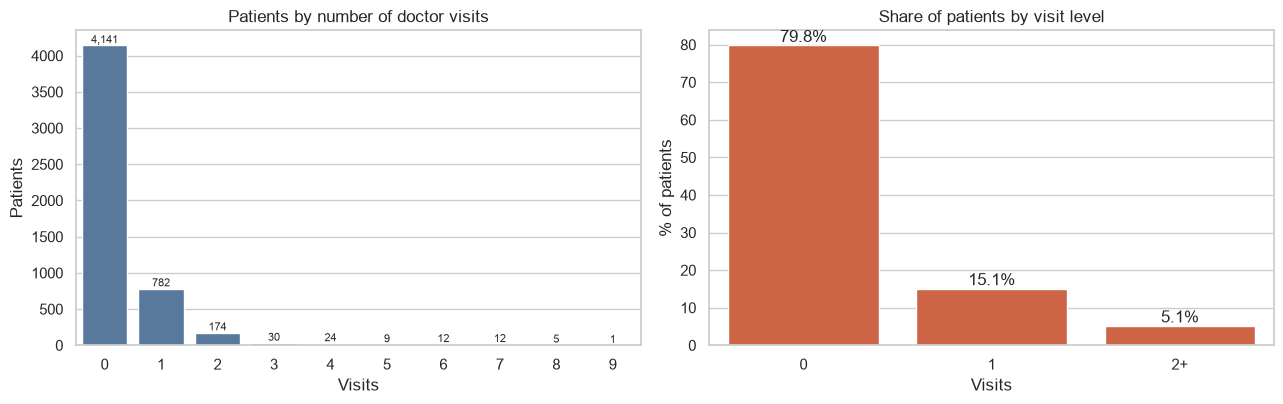

Average visits per person       : 0.302
Variance of visits              : 0.637  (larger than the mean -> counts are spread out / skewed)
People with zero visits         : 79.8%
People with at least one visit  : 20.2%
Most visits by one person       : 9


In [8]:
vc = df["visits"].value_counts().sort_index()
lvl = df["visit_level"].value_counts(normalize=True).reindex(["0", "1", "2+"]) * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.barplot(x=vc.index, y=vc.values, color=BLUE, ax=ax[0])
for i, v in enumerate(vc.values):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
ax[0].set(title="Patients by number of doctor visits", xlabel="Visits", ylabel="Patients")

sns.barplot(x=lvl.index, y=lvl.values, color=ORANGE, ax=ax[1])
for i, v in enumerate(lvl.values):
    ax[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom")
ax[1].set(title="Share of patients by visit level", xlabel="Visits", ylabel="% of patients")
plt.tight_layout()
plt.show()

print(f"Average visits per person       : {df.visits.mean():.3f}")
print(f"Variance of visits              : {df.visits.var():.3f}  (larger than the mean -> counts are spread out / skewed)")
print(f"People with zero visits         : {(df.visits == 0).mean():.1%}")
print(f"People with at least one visit  : {df.visited_any.mean():.1%}")
print(f"Most visits by one person       : {df.visits.max()}")

**What this means:** most people did not visit a doctor at all, and a small group visited several times.
Because of this skew, we use **two measures** throughout the rest of the notebook:

- **Mean visits** - the average count (captures heavy users).
- **% with at least one visit** - the share who used a doctor at all.

## 4. Visits vs categorical factors

Gender, chronic conditions and healthcare support are yes/no style columns.

patients  mean_visits  pct_any_visit
factor    group                                       
gender    female      2702        0.362         24.426
          male        2488        0.236         15.635
private   no          2892        0.307         20.367
          yes         2298        0.295         20.017
freepoor  no          4968        0.308         20.713
          yes          222        0.158          9.009
freerepat no          4099        0.258         17.175
          yes         1091        0.467         31.622
nchronic  no          3098        0.272         17.883
          yes         2092        0.346         23.662
lchronic  no          4585        0.262         18.255
          yes          605        0.603         35.041

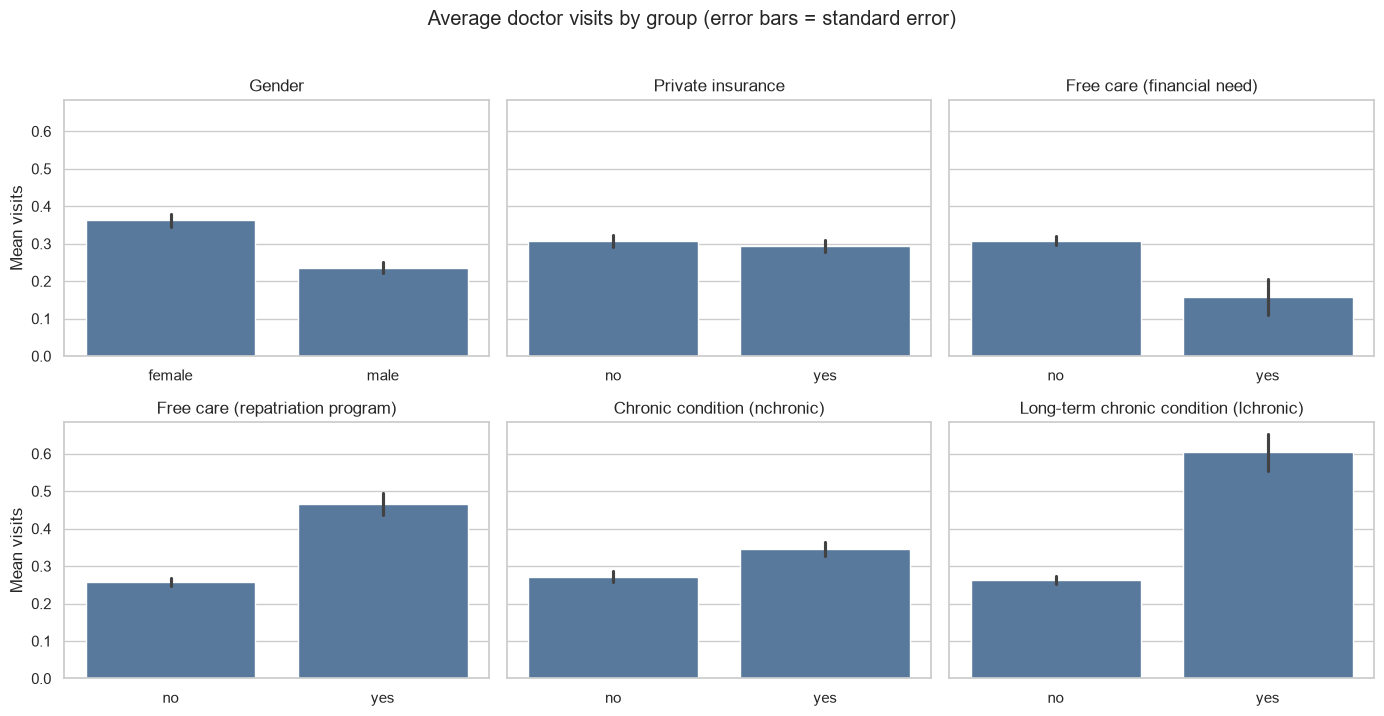

In [9]:
rows = []
for c in cat_cols:
    for lvl_name, g in df.groupby(c):
        rows.append({"factor": c, "group": lvl_name, "patients": len(g),
                     "mean_visits": g.visits.mean(), "pct_any_visit": 100 * g.visited_any.mean()})
cat_summary = pd.DataFrame(rows).set_index(["factor", "group"])
display(cat_summary)

titles = {"gender": "Gender", "private": "Private insurance", "freepoor": "Free care (financial need)",
          "freerepat": "Free care (repatriation program)", "nchronic": "Chronic condition (nchronic)",
          "lchronic": "Long-term chronic condition (lchronic)"}
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, c in zip(axes.ravel(), cat_cols):
    order = ["female", "male"] if c == "gender" else ["no", "yes"]
    sns.barplot(data=df, x=c, y="visits", order=order, errorbar="se", color=BLUE, ax=ax)
    ax.set(title=titles[c], xlabel="", ylabel="Mean visits")
fig.suptitle("Average doctor visits by group (error bars = standard error)", y=1.02)
plt.tight_layout()
plt.show()

### 4.1 Are these differences real or just chance?

We compare the two groups with a **Mann-Whitney U test** (suitable for skewed counts) and a **chi-square test** on "visited at least once".
A p-value below 0.05 means the difference is unlikely to be pure chance. It does **not** say how *large* or *important* the difference is,
so the table also shows the ratio of mean visits.

In [10]:
rows = []
for c in cat_cols:
    base, comp = ("male", "female") if c == "gender" else ("no", "yes")
    a = df.loc[df[c] == base, "visits"]
    b = df.loc[df[c] == comp, "visits"]
    p_mw = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
    p_chi = stats.chi2_contingency(pd.crosstab(df[c], df["visited_any"]))[1]
    rows.append({"factor": c, "compared": f"{comp} vs {base}", "mean_base": a.mean(), "mean_comp": b.mean(),
                 "ratio": b.mean() / a.mean(), "p_mannwhitney": p_mw, "p_chi2": p_chi,
                 "significant": "yes" if min(p_mw, p_chi) < 0.05 else "no"})
tests = pd.DataFrame(rows).set_index("factor")
tests_view = tests.copy()
for c in ["p_mannwhitney", "p_chi2"]:
    tests_view[c] = tests_view[c].map(lambda v: f"{v:.2e}")
display(tests_view)

,compared,mean_base,mean_comp,ratio,p_mannwhitney,p_chi2,significant
factor,,,,,,,
gender,female vs male,0.236,0.362,1.532,6.34e-15,4.35e-15,yes
private,yes vs no,0.307,0.295,0.958,7.62e-01,7.82e-01,no
freepoor,yes vs no,0.308,0.158,0.512,2.48e-05,3.14e-05,yes
freerepat,yes vs no,0.258,0.467,1.809,1.50e-25,7.13e-26,yes
nchronic,yes vs no,0.272,0.346,1.270,5.74e-07,4.42e-07,yes
lchronic,yes vs no,0.262,0.603,2.303,1.20e-23,7.27e-22,yes


## 5. Visits vs personal and financial factors (age, income)

By age group


,patients,mean_visits,pct_any_visit
age_group,,,
20 or less,752,0.213,15.160
21-30,1736,0.218,15.035
31-40,447,0.244,17.002
41-50,307,0.290,16.938
51-60,495,0.406,25.455
61+,1453,0.432,28.906


By income group


,patients,mean_visits,pct_any_visit
income_group,,,
Low (<=0.25),1638,0.398,25.641
Lower-mid (0.26-0.55),1329,0.305,20.090
Upper-mid (0.56-0.90),1485,0.230,16.566
High (>0.90),738,0.225,15.718


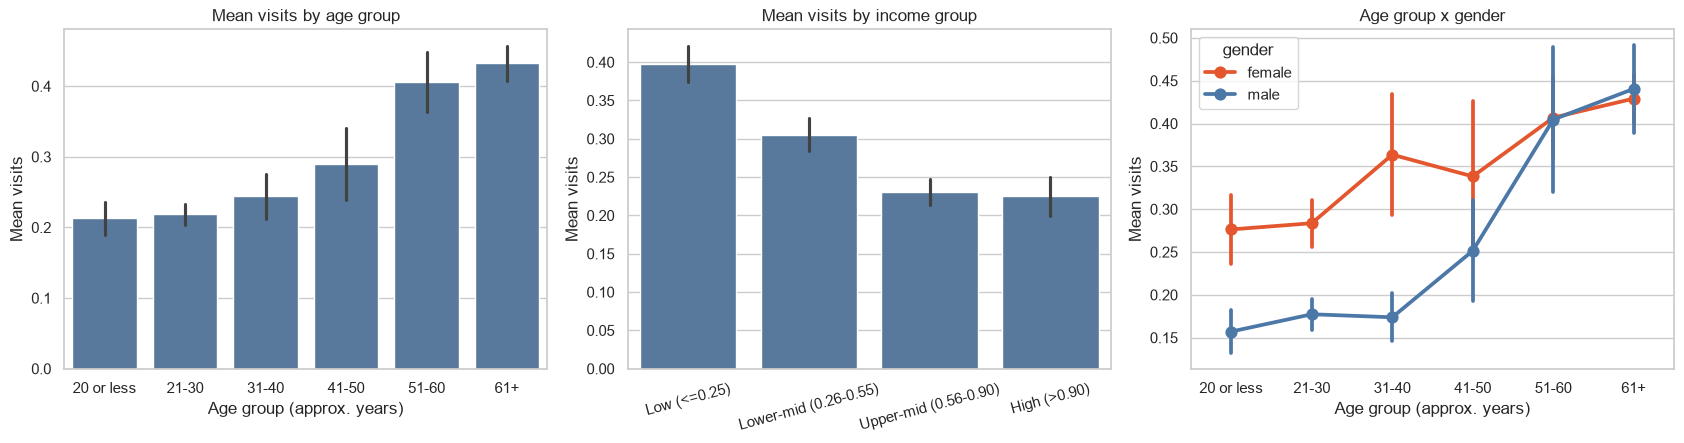

In [11]:
def rate_table(col):
    t = df.groupby(col, observed=True).agg(patients=("visits", "size"),
                                           mean_visits=("visits", "mean"),
                                           pct_any_visit=("visited_any", "mean"))
    t["pct_any_visit"] *= 100
    return t

print("By age group");    display(rate_table("age_group"))
print("By income group");  display(rate_table("income_group"))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
sns.barplot(data=df, x="age_group", y="visits", errorbar="se", color=BLUE, ax=axes[0])
axes[0].set(title="Mean visits by age group", xlabel="Age group (approx. years)", ylabel="Mean visits")

sns.barplot(data=df, x="income_group", y="visits", errorbar="se", color=BLUE, ax=axes[1])
axes[1].set(title="Mean visits by income group", xlabel="", ylabel="Mean visits")
axes[1].tick_params(axis="x", rotation=15)

sns.pointplot(data=df, x="age_group", y="visits", hue="gender", errorbar="se", ax=axes[2],
              palette={"female": ORANGE, "male": BLUE})
axes[2].set(title="Age group x gender", xlabel="Age group (approx. years)", ylabel="Mean visits")
plt.tight_layout()
plt.show()

## 6. Visits vs health factors (illness, health score, reduced activity)

By number of illnesses


,patients,mean_visits,pct_any_visit
illness,,,
0,1554,0.079,6.757
1,1638,0.295,19.597
2,946,0.404,27.273
3,542,0.421,30.627
4,274,0.577,36.496
5,236,0.814,41.949


By health score band


,patients,mean_visits,pct_any_visit
health_band,,,
0,3026,0.199,15.036
1,823,0.335,23.451
2,446,0.381,24.439
3-4,460,0.465,26.522
5-7,297,0.643,36.364
8-12,138,0.812,44.928


By reduced-activity days band


,patients,mean_visits,pct_any_visit
reduced_band,,,
0 days,4454,0.184,15.177
1-3,359,0.574,38.162
4-7,140,1.086,60.714
8-13,49,2.000,69.388
14,188,1.548,62.234


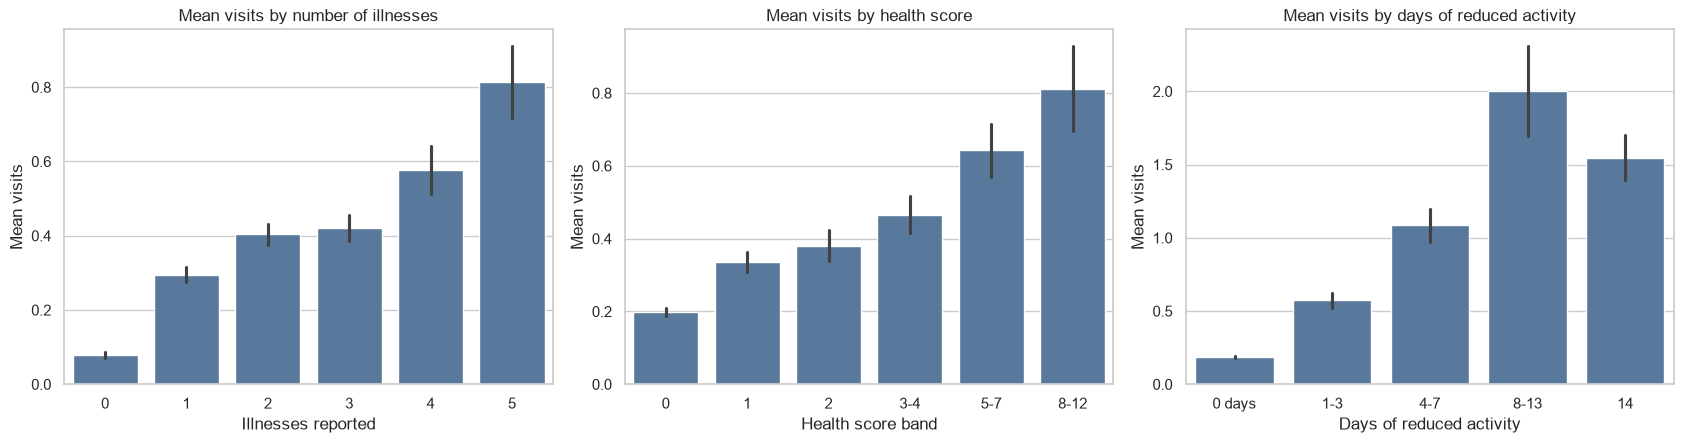

In [12]:
print("By number of illnesses");        display(rate_table("illness"))
print("By health score band");          display(rate_table("health_band"))
print("By reduced-activity days band"); display(rate_table("reduced_band"))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, col, ttl, xl in zip(axes,
                            ["illness", "health_band", "reduced_band"],
                            ["Mean visits by number of illnesses", "Mean visits by health score", "Mean visits by days of reduced activity"],
                            ["Illnesses reported", "Health score band", "Days of reduced activity"]):
    sns.barplot(data=df, x=col, y="visits", errorbar="se", color=BLUE, ax=ax)
    ax.set(title=ttl, xlabel=xl, ylabel="Mean visits")
plt.tight_layout()
plt.show()

## 7. Which factors move together with visits?

A **Spearman rank correlation** measures whether higher values of one column tend to go with higher values of another
(range -1 to +1). It works well here because visits are skewed counts. Yes/no columns are coded 0/1.

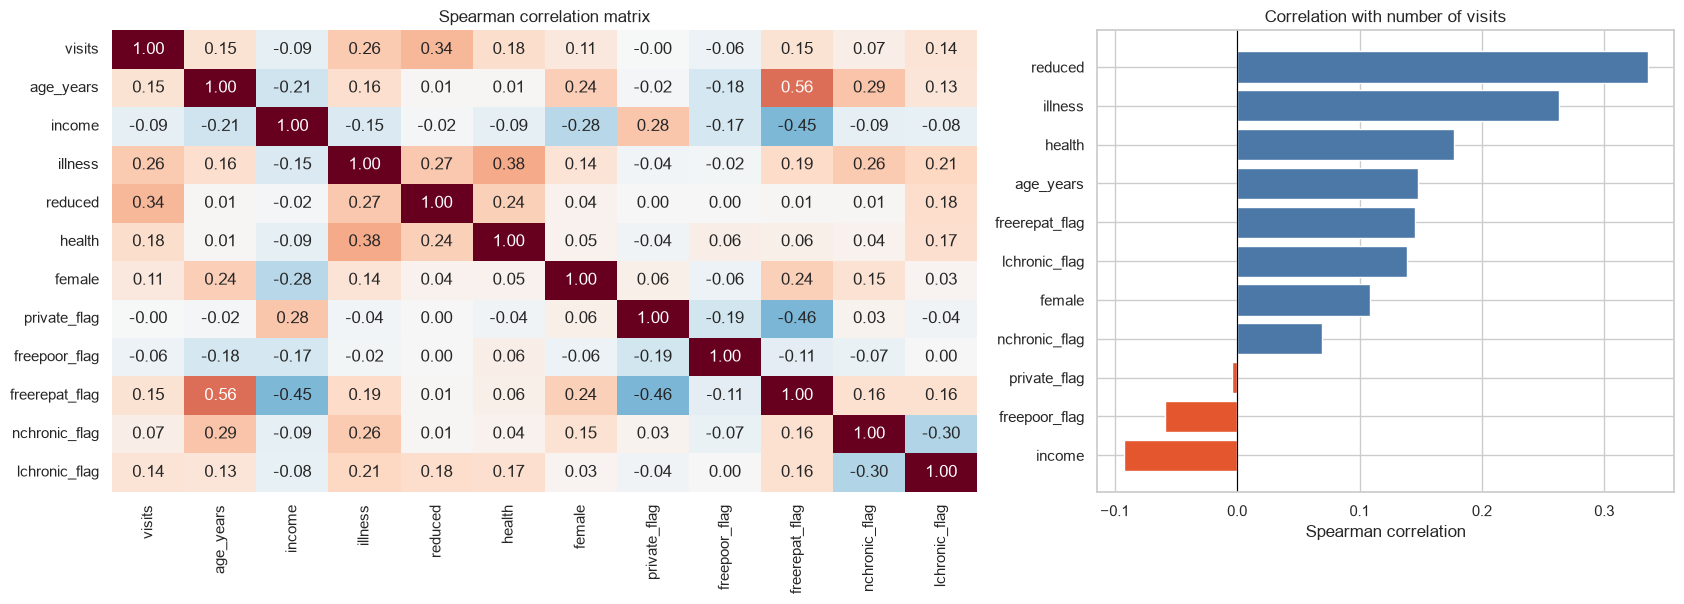

,correlation_with_visits
reduced,0.336
illness,0.263
health,0.178
age_years,0.148
freerepat_flag,0.145
lchronic_flag,0.139
female,0.108
nchronic_flag,0.069
private_flag,-0.004
freepoor_flag,-0.059


In [13]:
corr_cols = ["visits", "age_years", "income", "illness", "reduced", "health",
             "female", "private_flag", "freepoor_flag", "freerepat_flag", "nchronic_flag", "lchronic_flag"]
corr = df[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar=False, ax=ax[0])
ax[0].set_title("Spearman correlation matrix")

s = corr["visits"].drop("visits").sort_values()
ax[1].barh(s.index, s.values, color=np.where(s > 0, BLUE, ORANGE))
ax[1].axvline(0, color="black", lw=0.8)
ax[1].set(title="Correlation with number of visits", xlabel="Spearman correlation")
plt.tight_layout()
plt.show()

display(s.sort_values(ascending=False).to_frame("correlation_with_visits"))

**Reading the chart:** bars to the right (blue) are factors that go with *more* visits; bars to the left (orange) go with *fewer*.
All correlations are modest (the largest is around 0.3), which is normal for human behaviour: no single factor explains visits on its own.

## 8. Combining factors

Single comparisons can mislead when factors overlap. For example, people on the repatriation program may also be older.

Average age (approx. years) by repatriation-program status


,count,mean
freerepat,,
no,4099,34.249
yes,1091,64.643


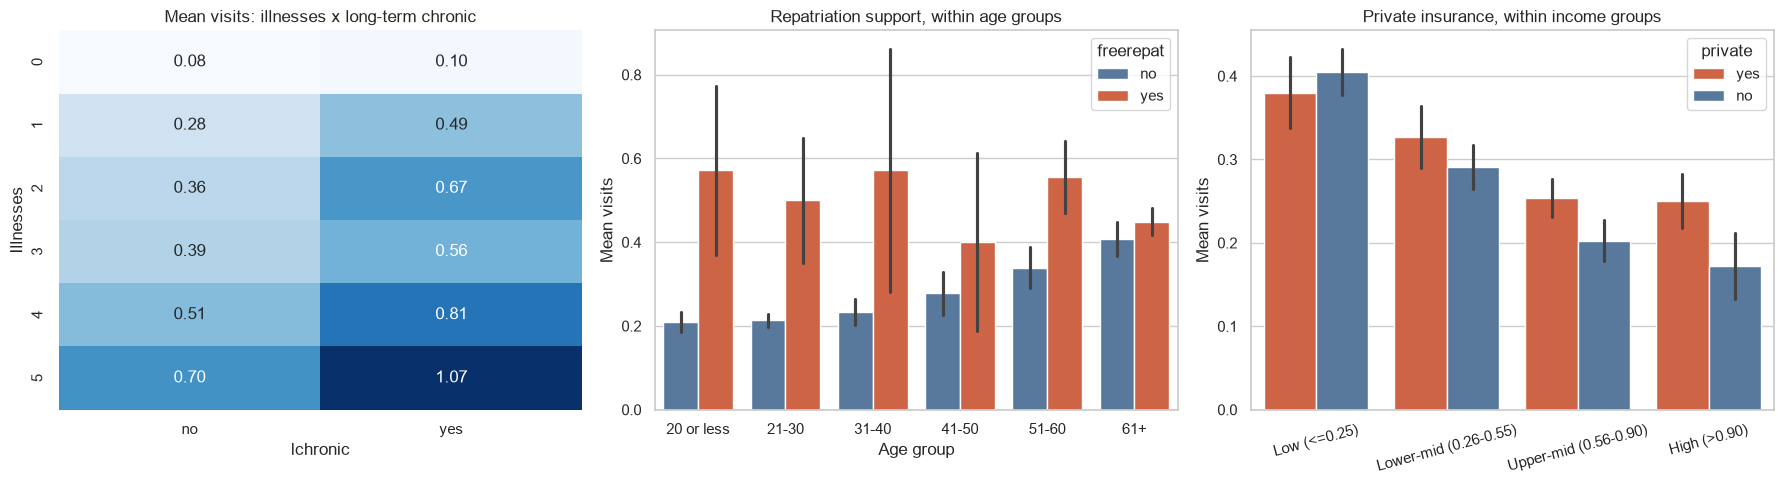

In [14]:
print("Average age (approx. years) by repatriation-program status")
display(df.groupby("freerepat")["age_years"].agg(["count", "mean"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# illness x long-term chronic condition
pv = df.pivot_table(index="illness", columns="lchronic", values="visits", aggfunc="mean")
sns.heatmap(pv, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Mean visits: illnesses x long-term chronic", xlabel="lchronic", ylabel="Illnesses")

# age group x repatriation support
sns.barplot(data=df, x="age_group", y="visits", hue="freerepat", errorbar="se",
            palette={"no": BLUE, "yes": ORANGE}, ax=axes[1])
axes[1].set(title="Repatriation support, within age groups", xlabel="Age group", ylabel="Mean visits")

# income group x private insurance
sns.barplot(data=df, x="income_group", y="visits", hue="private", errorbar="se",
            palette={"no": BLUE, "yes": ORANGE}, ax=axes[2])
axes[2].set(title="Private insurance, within income groups", xlabel="", ylabel="Mean visits")
axes[2].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 9. Bonus: which factors still matter when all are considered together?

A **logistic regression** estimates how each factor relates to *visiting a doctor at least once* **while holding the other factors fixed**.
All inputs are standardized, so each **odds ratio is "per 1 standard deviation"** (for yes/no columns this is roughly "yes vs no"):

- odds ratio **above 1** -> more likely to have visited
- odds ratio **below 1** -> less likely to have visited
- the further from 1, the stronger the association

This is for understanding patterns, not for diagnosing or predicting a specific person.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold

features = ["age_years", "income", "illness", "reduced", "health", "female",
            "private_flag", "freepoor_flag", "freerepat_flag", "nchronic_flag", "lchronic_flag"]
X = StandardScaler().fit_transform(df[features])
y = df["visited_any"]

model = LogisticRegression(max_iter=1000).fit(X, y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # shuffle: the file is sorted by age
auc = cross_val_score(LogisticRegression(max_iter=1000), X, y, cv=cv, scoring="roc_auc").mean()

odds = pd.Series(np.exp(model.coef_[0]), index=features).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(odds.index, odds.values - 1, left=1, color=np.where(odds > 1, BLUE, ORANGE))
ax.axvline(1, color="black", lw=0.8)
ax.set(title="Odds ratio of visiting a doctor (per 1 SD, other factors held fixed)", xlabel="Odds ratio (1 = no effect)")
plt.tight_layout()
plt.show()

display(odds.sort_values(ascending=False).to_frame("odds_ratio"))
print(f"Cross-validated ROC AUC: {auc:.2f}  (0.5 = guessing, 1.0 = perfect) -> factors help, but leave a lot unexplained")

ModuleNotFoundError: No module named 'sklearn'

## 10. Key insights - why do some people visit a doctor more often?

**The big picture.** About 80% of people made no doctor visit; the average is only 0.30 visits per person. Visits are driven mostly by **how unwell people are**, and less by who they are or what coverage they hold.

| Theme | What the data shows | Strength |
|---|---|---|
| **Reduced activity** (`reduced`) | 0 days affected: 0.18 average visits (15% visited). 1-3 days: 0.57 (38%). 4-7 days: 1.09 (61%) | **Strongest** (Spearman 0.34; highest odds ratio) |
| **Number of illnesses** (`illness`) | 0 illnesses: 0.08 average visits (7% visited) rising to 0.81 (42%) for 5 illnesses | **Strong** (0.26) |
| **Health score** (`health`) | Score 0: 0.20 average visits; score 8-12: 0.81. Higher scores go with more visits, consistent with a higher score meaning poorer health (check the dataset documentation) | Moderate (0.18) |
| **Chronic conditions** | Long-term chronic (`lchronic`): 0.60 vs 0.26 visits (2.3x). `nchronic`: 0.35 vs 0.27 (1.3x) | Moderate (`lchronic` > `nchronic`) |
| **Gender** | Women 0.36 vs men 0.24 average visits (1.5x); 24% vs 16% visited at least once | Moderate, clearly significant |
| **Age** | About 0.21-0.22 for people up to 30, rising to about 0.41-0.43 for people over 50 | Moderate (0.15) |
| **Income** | Lowest income group 0.40 vs highest 0.23 average visits. But the gap mostly disappears once health and other factors are held fixed (odds ratio about 0.98) | Weak on its own |
| **Private insurance** | No raw difference (0.29 vs 0.31, p = 0.76). Within the middle and high income groups, insured people visit slightly more, which is why the simple comparison hides it (small effect, odds ratio about 1.14) | None to small |
| **Free care: financial need** (`freepoor`) | Fewer visits (0.16 vs 0.31) - a small group of 222 people | Modest, small sample |
| **Free care: repatriation program** (`freerepat`) | More visits (0.47 vs 0.26), **but this group is much older** (average about 65 vs 34). Within age groups the gap is largest for younger people (small, noisy samples) and almost disappears for ages 61+ | Overlaps with age |

**Reading the factors together (section 9).** With every factor in one model, `reduced` and `illness` stay the strongest signals,
while income, age and the chronic-condition flags shrink. This suggests several simple patterns are partly *the same* effect seen from different angles
(older people have more illness and reduced activity, so they visit more). The model's cross-validated AUC of about 0.75 shows these columns carry real signal but leave much unexplained.

**Practical takeaway for a healthcare team:** people who report reduced-activity days and multiple illnesses, and those with long-term chronic conditions,
are the heaviest users of doctor visits and the natural group to plan capacity and follow-up around.

### Limitations - read before drawing conclusions

- **Association is not causation.** For example, illness may cause visits, but the data cannot show that private insurance or income *causes* more or fewer visits.
- **Small groups are noisy** (for example `freepoor` = 222 people; reduced activity 8-13 days = 49 people, which is why that bar is higher than the "14" bar).
- **Coarse measures:** `age` takes only 12 values and `income` only a few; our "age in years" is an interpretation of stored decimals.
- **Self-reported, one time window:** the period covered by the visit count is not stated in the file, and survey answers can be inaccurate.
- **Column meanings** (`health` direction, `nchronic` vs `lchronic`, `freerepat`) follow the simple definitions given in the problem statement; confirm them against the original data documentation if precision matters.

## 11. Key learning outcome

- Healthcare analytics turns a table of patient records into **patterns that explain behaviour** (here: doctor visits).
- Skewed count data (many zeros) is best described with **both the average and the share with at least one visit**.
- Comparing a target against **grouped factors** (age bands, income bands, illness counts) is a simple, powerful way to find patterns.
- Correlations and group comparisons show **association, not cause**; combining factors (sections 8-9) helps separate overlapping effects.
- Good analysts always state the **limitations** of their data before drawing conclusions.